# Dokumentexperimente auswerten

Dieses Notebook liest `report.json`, `plan.json` und bei Bedarf `container-metrics.jsonl` aus `results/documents/experiments/`. Es startet keine Benchmarks. Für Tabellen und Diagramme verwendet es pandas und Matplotlib.

**Start:** Im Repository `.venv/bin/pip install -r notebooks/requirements.txt` ausführen, das Notebook mit diesem Python-Kernel öffnen und alle Zellen der Reihe nach ausführen. Die erste Codezelle sucht das Repository vom aktuellen Arbeitsverzeichnis aus; das Notebook daher innerhalb des Repositorys starten. Ohne Auswahl werden die neuesten vollständigen Berichte je Profil und Fixture angezeigt. Für bestimmte Läufe `EXPERIMENT_IDS` in der ersten Codezelle setzen.

**Wichtig:** Jede Zeile der Lauf-Tabelle ist ein unabhängiger Messlauf. Die Matrix-Tabelle verwendet die vom Experiment-Controller berechneten Mediane der *Laufwerte*. Perzentile einzelner Requests werden nicht über Wiederholungen gemittelt. Schnellprofile mit nur einem Messpunkt und einer Wiederholung sind Funktionsprüfungen, keine belastbare Kapazitätsmessung.


In [12]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display


def find_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'benchmarks/documents/experiment.py').exists():
            return candidate
    raise FileNotFoundError('Repository nicht gefunden; Notebook im Repository öffnen.')


ROOT = find_root(Path.cwd().resolve())
EXPERIMENTS = ROOT / 'results/documents/experiments'

# Leer: je Profil den neuesten vollständigen Bericht anzeigen. IDs können auch
# explizit gesetzt werden, um ältere oder mehrere Wiederholungen zu vergleichen.
EXPERIMENT_IDS = []
LATEST_PER_PROFILE = True


def table(rows, columns, title=None):
    if title:
        display(Markdown(f'### {title}'))
    if not rows:
        display(Markdown('Keine passenden Daten vorhanden.'))
        return pd.DataFrame(columns=[key for key, _ in columns])
    frame = pd.DataFrame(rows).reindex(columns=[key for key, _ in columns])
    display(frame.rename(columns=dict(columns)))
    return frame


def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))


print('Repository:', ROOT)
print('Ergebnisse:', EXPERIMENTS)


Repository: /home/eseidinger/dev/storebench
Ergebnisse: /home/eseidinger/dev/storebench/results/documents/experiments


## Experimente auswählen

`EXPERIMENT_IDS` oben kann vollständige Ordnernamen enthalten. Ohne Auswahl wird für jede Kombination aus Profil und Fixture der neueste **vollständige** Bericht genommen. Fehlende oder noch laufende Berichte werden angezeigt, aber nicht in die Auswertung aufgenommen.


In [13]:
found = []
if EXPERIMENTS.exists():
    for path in sorted(EXPERIMENTS.glob('*/report.json')):
        report = read_json(path)
        plan_path = path.parent / 'plan.json'
        plan = read_json(plan_path) if plan_path.exists() else {}
        profile = plan.get('name') or Path(report.get('plan', path.parent.name)).stem
        found.append({'id': path.parent.name, 'path': path.parent, 'report': report,
                      'plan': plan, 'profile': profile,
                      'workload': report.get('workload', plan.get('workload', 'read')),
                      'fixture': report.get('input_profile'),
                      'complete': report.get('summary', {}).get('complete', False)})

table([{'id': x['id'], 'profile': x['profile'], 'workload': x['workload'],
        'fixture': x['fixture'], 'runs': len(x['report'].get('runs', [])),
        'complete': x['complete']} for x in found],
      [('id', 'Ergebnisordner'), ('profile', 'Profil'), ('workload', 'Art'),
       ('fixture', 'Fixture'), ('runs', 'Läufe'), ('complete', 'Vollständig')],
      'Gefundene Berichte')

if EXPERIMENT_IDS:
    missing = sorted(set(EXPERIMENT_IDS) - {x['id'] for x in found})
    if missing:
        raise ValueError(f'Unbekannte EXPERIMENT_IDS: {missing}')
    selected = [x for x in found if x['id'] in EXPERIMENT_IDS and x['complete']]
else:
    complete = [x for x in found if x['complete']]
    if LATEST_PER_PROFILE:
        latest = {}
        for x in complete:
            latest[(x['workload'], x['profile'], x['fixture'])] = x
        selected = sorted(latest.values(), key=lambda x: x['id'])
    else:
        selected = complete
print('Ausgewählte vollständige Experimente:', len(selected))


### Gefundene Berichte

,Ergebnisordner,Profil,Art,Fixture,Läufe,Vollständig
0,20261104T132127Z-read-7d03d9ad,read-only-quick-v1,read,storefront-quick-v1,2,True
1,20261104T132155Z-write-174ad813,catalog-maintenance-write-quick-v1,write,storefront-quick-v1,2,True
2,20261104T132224Z-write-84aa3a68,contested-stock-write-quick-v1,write,storefront-quick-v1,2,True


Ausgewählte vollständige Experimente: 3


## Messpunkte und unabhängige Läufe

`Qualifiziert` berücksichtigt Korrektheit, p95, Fehlerquote, Ressourcen- und Sample-Prüfungen. `Abgeschlossen` beschreibt den technischen Laufstatus. Ein technisch abgeschlossener Lauf kann die Qualitätsgrenze verfehlen. `p95` bezieht sich bei Schreiblasten auf erfolgreiche logische Schreibvorgänge.


In [14]:
run_rows = []
for experiment in selected:
    for run in experiment['report'].get('runs', []):
        measure = run.get('measure') or {}
        run_rows.append({'experiment': experiment['id'], 'profile': experiment['profile'],
                         'art': run.get('kind'), 'store': run.get('store'),
                         'workers': run.get('concurrency'), 'rate': run.get('rate_per_second'),
                         'repetition': run.get('repetition', run.get('pair')),
                         'sampler': run.get('sampler_enabled'),
                         'status': run.get('status'), 'qualifies': run.get('qualifies'),
                         'completed_per_s': measure.get('completed_within_window_per_second'),
                         'p95_ms': measure.get('end_to_end_p95_ns', 0) / 1e6
                         if measure.get('end_to_end_p95_ns') is not None else None,
                         'failure_rate': measure.get('technical_failure_rate',
                                                     measure.get('offered_failure_rate')),
                         'setup_s': run.get('setup_ns', 0) / 1e9
                         if run.get('setup_ns') is not None else None,
                         'sample_ok': run.get('sample_interval_ok')})
table(run_rows,
      [('profile', 'Profil'), ('art', 'Laufart'), ('store', 'Store'), ('workers', 'Worker'),
       ('rate', 'Angeboten/s'), ('repetition', 'Wdh./Paar'), ('sampler', 'Sampler'),
       ('status', 'Status'), ('qualifies', 'Qualifiziert'),
       ('completed_per_s', 'Abgeschlossen/s'), ('p95_ms', 'p95 ms'),
       ('failure_rate', 'Fehlerquote'), ('sample_ok', 'Sample-Abstand OK')],
      'Einzelläufe')

matrix_rows = []
for experiment in selected:
    for point in experiment['report']['summary'].get('matrix', []):
        matrix_rows.append({'experiment': experiment['id'], 'profile': experiment['profile'],
                            'workload': experiment['workload'], **point})
table(matrix_rows,
      [('profile', 'Profil'), ('store', 'Store'), ('concurrency', 'Worker'),
       ('rate_per_second', 'Angeboten/s'), ('runs', 'Läufe'),
       ('all_qualify', 'Alle qualifiziert'),
       ('completed_per_second_median', 'Abgeschlossen/s Median'),
       ('run_p95_ms_median', 'Lauf-p95 ms Median'),
       ('setup_seconds_median', 'Setup s Median'),
       ('preparation_seconds_median', 'Vorbereitung s Median'),
       ('index_file_mib_median', 'Index MiB Median')],
      'Matrix: Mediane unabhängiger Läufe')


### Einzelläufe

,Profil,Laufart,Store,Worker,Angeboten/s,Wdh./Paar,Sampler,Status,Qualifiziert,Abgeschlossen/s,p95 ms,Fehlerquote,Sample-Abstand OK
0,read-only-quick-v1,matrix,postgres,4,20,1,True,passed,True,20.0,2.906977,0.0,True
1,read-only-quick-v1,matrix,couchdb,4,20,1,True,passed,True,20.0,36.027981,0.0,True
2,catalog-maintenance-write-quick-v1,matrix,postgres,4,20,1,True,passed,True,19.6,4.917095,0.0,True
3,catalog-maintenance-write-quick-v1,matrix,couchdb,4,20,1,True,passed,True,19.6,17.301468,0.0,True
4,contested-stock-write-quick-v1,matrix,postgres,4,20,1,True,passed,True,20.0,4.528369,0.0,True
5,contested-stock-write-quick-v1,matrix,couchdb,4,20,1,True,passed,True,20.0,20.944542,0.0,True


### Matrix: Mediane unabhängiger Läufe

,Profil,Store,Worker,Angeboten/s,Läufe,Alle qualifiziert,Abgeschlossen/s Median,Lauf-p95 ms Median,Setup s Median,Vorbereitung s Median,Index MiB Median
0,read-only-quick-v1,couchdb,4,20,1,True,20.0,36.027981,0.421116,0.554551,0.133470
1,read-only-quick-v1,postgres,4,20,1,True,20.0,2.906977,0.059172,0.014945,0.125000
2,catalog-maintenance-write-quick-v1,couchdb,4,20,1,True,19.6,17.301468,0.245396,0.533187,0.134250
3,catalog-maintenance-write-quick-v1,postgres,4,20,1,True,19.6,4.917095,0.042858,0.008073,0.125000
4,contested-stock-write-quick-v1,couchdb,4,20,1,True,20.0,20.944542,0.237333,0.557805,0.132679
5,contested-stock-write-quick-v1,postgres,4,20,1,True,20.0,4.528369,0.041212,0.007847,0.125000


,profile,store,concurrency,rate_per_second,runs,all_qualify,completed_per_second_median,run_p95_ms_median,setup_seconds_median,preparation_seconds_median,index_file_mib_median
0,read-only-quick-v1,couchdb,4,20,1,True,20.0,36.027981,0.421116,0.554551,0.133470
1,read-only-quick-v1,postgres,4,20,1,True,20.0,2.906977,0.059172,0.014945,0.125000
2,catalog-maintenance-write-quick-v1,couchdb,4,20,1,True,19.6,17.301468,0.245396,0.533187,0.134250
3,catalog-maintenance-write-quick-v1,postgres,4,20,1,True,19.6,4.917095,0.042858,0.008073,0.125000
4,contested-stock-write-quick-v1,couchdb,4,20,1,True,20.0,20.944542,0.237333,0.557805,0.132679
5,contested-stock-write-quick-v1,postgres,4,20,1,True,20.0,4.528369,0.041212,0.007847,0.125000


## Stores direkt vergleichen

Die Tabelle stellt für jeden Messpunkt die vom Experiment-Controller berechneten Mediane beider Stores gegenüber. Positive Prozentwerte sprechen für PostgreSQL, negative für CouchDB: Beim Durchsatz ist mehr besser, beim p95 weniger. Ein Prozentvergleich erscheint nur, wenn **beide** Stores am Messpunkt alle Qualitätsgrenzen erfüllen. Bei Schnellprofilen mit nur einer Wiederholung sind die Werte lediglich eine Funktionsprobe.


In [15]:
points = pd.DataFrame(matrix_rows)
if points.empty:
    display(Markdown('Keine Messpunkte zum Vergleichen vorhanden.'))
else:
    keys = ['experiment', 'profile', 'workload', 'concurrency', 'rate_per_second']
    metrics = ['completed_per_second_median', 'run_p95_ms_median', 'all_qualify']
    comparison = points.set_index(keys + ['store'])[metrics].unstack('store')
    comparison.columns = [f'{metric}_{store}' for metric, store in comparison.columns]
    comparison = comparison.reset_index()

    for store in ('postgres', 'couchdb'):
        for metric in metrics:
            column = f'{metric}_{store}'
            if column not in comparison:
                comparison[column] = pd.NA

    both_qualify = (comparison['all_qualify_postgres'].eq(True) &
                    comparison['all_qualify_couchdb'].eq(True))
    pg_rate = pd.to_numeric(comparison['completed_per_second_median_postgres'], errors='coerce')
    couch_rate = pd.to_numeric(comparison['completed_per_second_median_couchdb'], errors='coerce')
    pg_p95 = pd.to_numeric(comparison['run_p95_ms_median_postgres'], errors='coerce')
    couch_p95 = pd.to_numeric(comparison['run_p95_ms_median_couchdb'], errors='coerce')
    comparison['rate_advantage_pg_pct'] = ((pg_rate / couch_rate.replace(0, float('nan')) - 1)
                                            * 100).where(both_qualify).round(1)
    comparison['p95_advantage_pg_pct'] = ((1 - pg_p95 / couch_p95.replace(0, float('nan')))
                                           * 100).where(both_qualify).round(1)
    comparison['both_qualify'] = both_qualify

    columns = {
        'profile': 'Profil', 'workload': 'Last', 'concurrency': 'Worker',
        'rate_per_second': 'Angeboten/s',
        'completed_per_second_median_postgres': 'Postgres abgeschlossen/s',
        'completed_per_second_median_couchdb': 'CouchDB abgeschlossen/s',
        'run_p95_ms_median_postgres': 'Postgres p95 ms',
        'run_p95_ms_median_couchdb': 'CouchDB p95 ms',
        'both_qualify': 'Beide qualifiziert',
        'rate_advantage_pg_pct': 'Durchsatzvorteil Postgres %',
        'p95_advantage_pg_pct': 'p95-Vorteil Postgres %',
    }
    display(comparison[['experiment', *columns]].rename(columns=columns))


,experiment,Profil,Last,Worker,Angeboten/s,Postgres abgeschlossen/s,CouchDB abgeschlossen/s,Postgres p95 ms,CouchDB p95 ms,Beide qualifiziert,Durchsatzvorteil Postgres %,p95-Vorteil Postgres %
0,20261104T132127Z-read-7d03d9ad,read-only-quick-v1,read,4,20,20.0,20.0,2.906977,36.027981,True,0.0,91.9
1,20261104T132155Z-write-174ad813,catalog-maintenance-write-quick-v1,write,4,20,19.6,19.6,4.917095,17.301468,True,0.0,71.6
2,20261104T132224Z-write-84aa3a68,contested-stock-write-quick-v1,write,4,20,20.0,20.0,4.528369,20.944542,True,0.0,78.4


## Durchsatz und Latenz

Die Diagramme zeigen für jedes ausgewählte Experiment die Medianwerte der Messpunkte. Jede Workerzahl wird separat dargestellt; Punkte sind angebotene Raten. Ein einzelner Punkt eines Schnellprofils bildet keine Lastkurve.


### read-only-quick-v1 — 20261104T132127Z-read-7d03d9ad

**4 Worker**

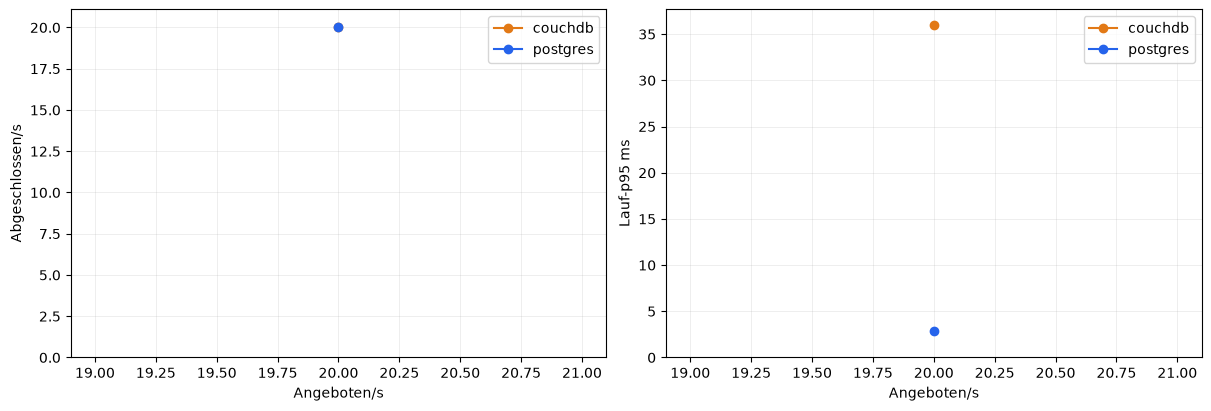

### catalog-maintenance-write-quick-v1 — 20261104T132155Z-write-174ad813

**4 Worker**

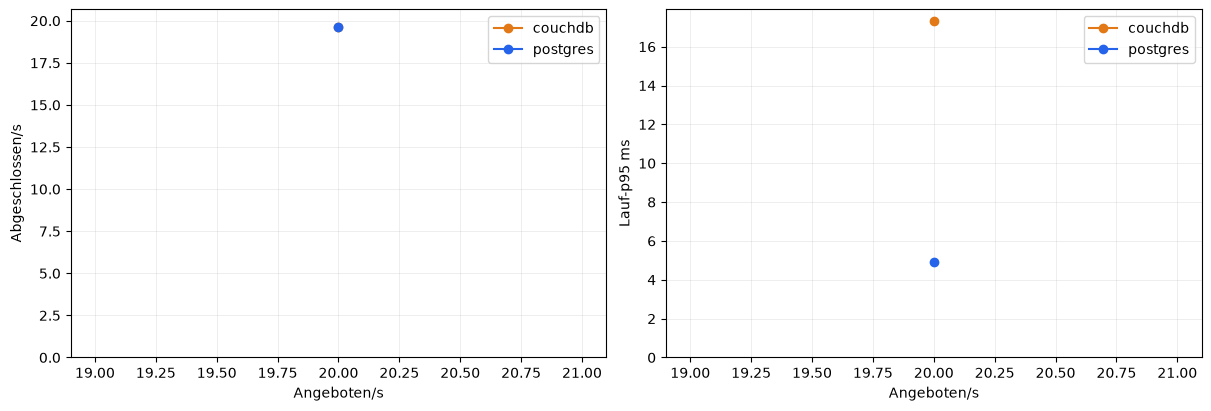

### contested-stock-write-quick-v1 — 20261104T132224Z-write-84aa3a68

**4 Worker**

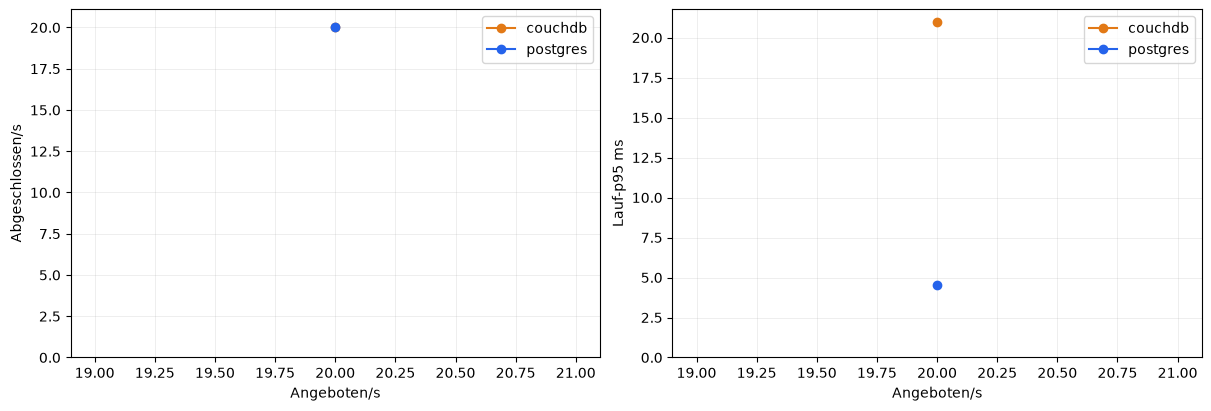

In [16]:
colors = {'postgres': '#2563eb', 'couchdb': '#e27916'}
for experiment in selected:
    display(Markdown(f"### {experiment['profile']} — {experiment['id']}"))
    points = pd.DataFrame(experiment['report']['summary'].get('matrix', []))
    if points.empty:
        display(Markdown('Keine Messpunkte vorhanden.'))
        continue
    for workers, relevant in points.groupby('concurrency', sort=True):
        display(Markdown(f'**{workers} Worker**'))
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
        for ax, (key, label) in zip(axes, [
            ('completed_per_second_median', 'Abgeschlossen/s'),
            ('run_p95_ms_median', 'Lauf-p95 ms'),
        ]):
            for store, group in relevant.groupby('store'):
                values = group[['rate_per_second', key]].copy()
                values[key] = pd.to_numeric(values[key], errors='coerce')
                values = values.dropna().sort_values('rate_per_second')
                if not values.empty:
                    ax.plot(values['rate_per_second'], values[key], marker='o',
                            label=store, color=colors.get(store))
            ax.set(xlabel='Angeboten/s', ylabel=label, ylim=(0, None))
            ax.grid(alpha=0.3)
            if ax.has_data():
                ax.legend()
        plt.show()


## Kapazität und Sampler-Vergleich

„Höchste qualifizierte Rate“ ist nur die höchste **getestete** Rate pro Workerzahl. Wenn die höchste konfigurierte Rate qualifiziert, wurde die Kapazitätsgrenze noch nicht eingegrenzt. Ein leerer Sampler-Vergleich bedeutet, dass `pairs: 0` gesetzt war.


In [17]:
capacity = []
sampler = []
for experiment in selected:
    summary = experiment['report']['summary']
    capacity.extend({'profile': experiment['profile'], **row}
                    for row in summary.get('capacity', []))
    sampler.extend({'profile': experiment['profile'], **row}
                   for row in summary.get('overhead_pairs', []))
table(capacity,
      [('profile', 'Profil'), ('store', 'Store'), ('concurrency', 'Worker'),
       ('highest_tested_qualifying_rate', 'Höchste qualifizierte Rate'),
       ('completed_per_second_median', 'Abgeschlossen/s Median'),
       ('highest_configured_rate_qualifies', 'Oberster Testpunkt qualifiziert')],
      'Getestete Kapazität')
table(sampler,
      [('profile', 'Profil'), ('store', 'Store'), ('pair', 'Paar'),
       ('status', 'Status'), ('p95_on_over_off', 'p95 an/aus'),
       ('throughput_on_over_off', 'Durchsatz an/aus')],
      'Sampler-Overhead-Paare')


### Getestete Kapazität

,Profil,Store,Worker,Höchste qualifizierte Rate,Abgeschlossen/s Median,Oberster Testpunkt qualifiziert
0,read-only-quick-v1,postgres,4,20,20.0,True
1,read-only-quick-v1,couchdb,4,20,20.0,True
2,catalog-maintenance-write-quick-v1,postgres,4,20,19.6,True
3,catalog-maintenance-write-quick-v1,couchdb,4,20,19.6,True
4,contested-stock-write-quick-v1,postgres,4,20,20.0,True
5,contested-stock-write-quick-v1,couchdb,4,20,20.0,True


### Sampler-Overhead-Paare

Keine passenden Daten vorhanden.

,profile,store,pair,status,p95_on_over_off,throughput_on_over_off


## Schreiblast: technische und fachliche Ergebnisse

`conflict_exhausted`, `dropped` und unerwartete Fehler zählen als technische Fehler. `condition_rejected` und `duplicate_rejected` sind erwartete fachliche Ablehnungen. Die Zahlen der Matrix sind Mediane der Zähler pro unabhängigen Lauf.


In [18]:
writes = [row for row in matrix_rows if row['workload'] == 'write']
table(writes,
      [('profile', 'Profil'), ('store', 'Store'), ('concurrency', 'Worker'),
       ('rate_per_second', 'Angeboten/s'),
       ('technical_failure_rate_median', 'Techn. Fehlerquote'),
       ('conflicts_per_run_median', 'Konflikte/Lauf'),
       ('conflict_exhausted_per_run_median', 'Ausgeschöpfte Konflikte/Lauf'),
       ('condition_rejected_per_run_median', 'Bestand abgelehnt/Lauf'),
       ('duplicate_rejected_per_run_median', 'Duplikat abgelehnt/Lauf'),
       ('dropped_per_run_median', 'Verworfen/Lauf')],
      'Schreibresultate')


### Schreibresultate

,Profil,Store,Worker,Angeboten/s,Techn. Fehlerquote,Konflikte/Lauf,Ausgeschöpfte Konflikte/Lauf,Bestand abgelehnt/Lauf,Duplikat abgelehnt/Lauf,Verworfen/Lauf
0,catalog-maintenance-write-quick-v1,couchdb,4,20,0.0,0,0,0,2,0
1,catalog-maintenance-write-quick-v1,postgres,4,20,0.0,0,0,0,2,0
2,contested-stock-write-quick-v1,couchdb,4,20,0.0,0,0,0,0,0
3,contested-stock-write-quick-v1,postgres,4,20,0.0,0,0,0,0,0


,profile,store,concurrency,rate_per_second,technical_failure_rate_median,conflicts_per_run_median,conflict_exhausted_per_run_median,condition_rejected_per_run_median,duplicate_rejected_per_run_median,dropped_per_run_median
0,catalog-maintenance-write-quick-v1,couchdb,4,20,0.0,0,0,0,2,0
1,catalog-maintenance-write-quick-v1,postgres,4,20,0.0,0,0,0,2,0
2,contested-stock-write-quick-v1,couchdb,4,20,0.0,0,0,0,0,0
3,contested-stock-write-quick-v1,postgres,4,20,0.0,0,0,0,0,0


## Ressourcen und Anfragegruppen

CPU ist der Mittelwert in Kernen während der Messphase; Speicher ist der gemessene Höchstwert. Fehlen Samples, bleiben die Felder leer. Gruppen-p95-Werte stammen jeweils aus einem einzelnen Lauf und werden nicht über Läufe zusammengeführt.


In [19]:
resources = []
groups = []
for experiment in selected:
    for run in experiment['report'].get('runs', []):
        if run.get('kind') != 'matrix':
            continue
        summary = run.get('resource_summary') or {}
        resources.append({'profile': experiment['profile'], 'store': run['store'],
                          'workers': run['concurrency'], 'rate': run['rate_per_second'],
                          'repetition': run.get('repetition'),
                          'samples': run.get('resource_sample_count'),
                          'max_interval_s': (run.get('actual_sample_intervals') or {}).get('max_seconds'),
                          'store_cpu': (summary.get('store') or {}).get('cpu_cores_mean'),
                          'store_mem_mib': ((summary.get('store') or {}).get('memory_peak_bytes') / 2**20
                          if (summary.get('store') or {}).get('memory_peak_bytes') is not None else None),
                          'client_cpu': (summary.get('client') or {}).get('cpu_cores_mean'),
                          'client_mem_mib': ((summary.get('client') or {}).get('memory_peak_bytes') / 2**20
                          if (summary.get('client') or {}).get('memory_peak_bytes') is not None else None)})
        for name, group in (run.get('measure') or {}).get('groups', {}).items():
            groups.append({'profile': experiment['profile'], 'store': run['store'],
                           'workers': run['concurrency'], 'rate': run['rate_per_second'],
                           'repetition': run.get('repetition'), 'group': name,
                           'completed': group.get('completed'),
                           'p95_ms': group.get('end_to_end_p95_ns', 0) / 1e6
                           if group.get('end_to_end_p95_ns') is not None else None,
                           'errors': group.get('errors'), 'statuses': group.get('statuses')})
table(resources,
      [('profile', 'Profil'), ('store', 'Store'), ('workers', 'Worker'),
       ('rate', 'Angeboten/s'), ('repetition', 'Wdh.'), ('samples', 'Samples'),
       ('max_interval_s', 'Max. Abstand s'), ('store_cpu', 'Store CPU-Kerne'),
       ('store_mem_mib', 'Store MiB'), ('client_cpu', 'Client CPU-Kerne'),
       ('client_mem_mib', 'Client MiB')],
      'Ressourcen pro Lauf')
table(groups,
      [('profile', 'Profil'), ('store', 'Store'), ('repetition', 'Wdh.'),
       ('group', 'Anfragegruppe'), ('completed', 'Abgeschlossen'),
       ('p95_ms', 'p95 ms'), ('errors', 'Fehler'), ('statuses', 'Schreibstatus')],
      'Anfragegruppen pro Lauf')


### Ressourcen pro Lauf

,Profil,Store,Worker,Angeboten/s,Wdh.,Samples,Max. Abstand s,Store CPU-Kerne,Store MiB,Client CPU-Kerne,Client MiB
0,read-only-quick-v1,postgres,4,20,1,6,1.006670,0.020436,63.839844,0.014913,46.304688
1,read-only-quick-v1,couchdb,4,20,1,7,1.004511,0.194209,220.605469,0.027387,46.230469
2,catalog-maintenance-write-quick-v1,postgres,4,20,1,6,1.005222,0.023516,30.214844,0.014930,46.984375
3,catalog-maintenance-write-quick-v1,couchdb,4,20,1,8,1.005001,0.170734,171.714844,0.027375,45.976562
4,contested-stock-write-quick-v1,postgres,4,20,1,6,1.004382,0.021821,30.027344,0.014937,46.863281
5,contested-stock-write-quick-v1,couchdb,4,20,1,8,1.005526,0.204981,176.375000,0.037311,46.371094


### Anfragegruppen pro Lauf

,Profil,Store,Wdh.,Anfragegruppe,Abgeschlossen,p95 ms,Fehler,Schreibstatus
0,read-only-quick-v1,postgres,1,P1:hot,21,1.308260,0.0,None
1,read-only-quick-v1,postgres,1,P1:uniform,26,1.201065,0.0,None
2,read-only-quick-v1,postgres,1,P2:broad,6,3.488923,0.0,None
3,read-only-quick-v1,postgres,1,P2:empty,10,1.409910,0.0,None
4,read-only-quick-v1,postgres,1,P2:medium,9,2.199741,0.0,None
5,read-only-quick-v1,postgres,1,P2:rare,7,1.573421,0.0,None
6,read-only-quick-v1,postgres,1,P3:depth-1,9,1.845561,0.0,None
7,read-only-quick-v1,postgres,1,P3:depth-10,4,1.863879,0.0,None
8,read-only-quick-v1,postgres,1,P3:depth-3,2,1.579386,0.0,None
9,read-only-quick-v1,postgres,1,P4,6,2.199174,0.0,None


,profile,store,repetition,group,completed,p95_ms,errors,statuses
0,read-only-quick-v1,postgres,1,P1:hot,21,1.308260,0.0,None
1,read-only-quick-v1,postgres,1,P1:uniform,26,1.201065,0.0,None
2,read-only-quick-v1,postgres,1,P2:broad,6,3.488923,0.0,None
3,read-only-quick-v1,postgres,1,P2:empty,10,1.409910,0.0,None
4,read-only-quick-v1,postgres,1,P2:medium,9,2.199741,0.0,None
5,read-only-quick-v1,postgres,1,P2:rare,7,1.573421,0.0,None
6,read-only-quick-v1,postgres,1,P3:depth-1,9,1.845561,0.0,None
7,read-only-quick-v1,postgres,1,P3:depth-10,4,1.863879,0.0,None
8,read-only-quick-v1,postgres,1,P3:depth-3,2,1.579386,0.0,None
9,read-only-quick-v1,postgres,1,P4,6,2.199174,0.0,None


## Rohsamples eines Laufs

Optional: Den Namen eines `run-*`-Ordners in `SAMPLE_RUN` eintragen. Ohne Auswahl wird der erste Matrixlauf verwendet. Das Diagramm zeigt den Speicherverbrauch während der Messphase; die JSONL-Datei bleibt die Quelle für weitere Analysen.


**20261104T132127Z-read-7d03d9ad / run-001-matrix-postgres** — 10 Messphasen-Samples

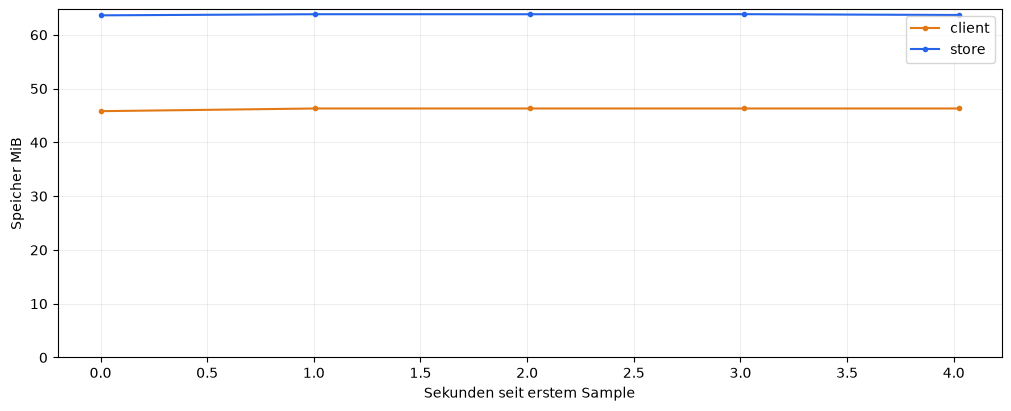

In [20]:
SAMPLE_RUN = None
candidates = [(experiment, run) for experiment in selected
              for run in experiment['report'].get('runs', []) if run.get('kind') == 'matrix']
chosen = next(((exp, run) for exp, run in candidates
               if Path(run.get('output', '')).name == SAMPLE_RUN), None) if SAMPLE_RUN else None
if chosen is None and candidates:
    chosen = candidates[0]
if chosen:
    experiment, run = chosen
    sample_path = experiment['path'] / Path(run['output']).name / 'container-metrics.jsonl'
    samples = pd.read_json(sample_path, lines=True)
    samples = samples.loc[(samples['status'] == 'ok') &
                          (samples['phase'] == 'measure') &
                          samples['memory_usage_bytes'].notna()].copy()
    display(Markdown(f"**{experiment['id']} / {Path(run['output']).name}** — "
                     f"{len(samples)} Messphasen-Samples"))
    if not samples.empty:
        samples['seconds'] = (samples['sampled_monotonic_ns'] -
                              samples['sampled_monotonic_ns'].min()) / 1e9
        samples['memory_mib'] = samples['memory_usage_bytes'] / 2**20
        fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
        for role, group in samples.groupby('role'):
            color = colors.get({'store': 'postgres', 'client': 'couchdb'}.get(role))
            group = group.sort_values('seconds')
            ax.plot(group['seconds'], group['memory_mib'], marker='.',
                    label=role, color=color)
        ax.set(xlabel='Sekunden seit erstem Sample', ylabel='Speicher MiB', ylim=(0, None))
        ax.grid(alpha=0.3)
        ax.legend()
        plt.show()
    else:
        display(Markdown('Keine passenden Messphasen-Samples vorhanden.'))
else:
    display(Markdown('Keine Matrixläufe vorhanden.'))
